# Building a catalog at 1.6 < z < 2.0

Notebook 01 for 1.6 < z < 2.0, with the same thresholds, base catalog, rescaling and doublet rule. Hα leaves the grism
at z = 1.94 (19 300 Å), and [O III] λ5007 carries the range to z = 2.0. The catalog here is therefore of every galaxy
(`line="all"`): Hα and [O III] emitters together, each with the redshift of the line it was identified by.
`line="Ha"` or `line="OIII_5007"` would keep one of them only.

Run it on a CPU node, from the package directory: `sbatch scripts/run_notebook.sh notebooks/02_catalog_z1p6_2p0.ipynb`
(about 3 minutes). The catalogs go to `$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, LineFactors, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)

# The rescaling of the oxygen lines (introduction of notebook 01): [O III] gets a scatter of 0.19 dex, and [O II] is
# brightened by 0.25 dex with a scatter of 0.11 dex. One deviate per galaxy; the other lines keep their raw fluxes.
RESCALING = LineFactors(log_offsets={"OII_3727": 0.25}, scatter={"OIII_5007": 0.19, "OIII_4959": 0.19, "OII_3727": 0.11})
print(RESCALING.describe(base.line_set))


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>
line_factors rescaling: OIII_5007 x1.000 ±0.19 dex, OIII_4959 x1.000 ±0.19 dex, OII_3727 x1.778 ±0.11 dex


## Step 1: the proposal

The sample is every detected galaxy at 1.6 < z < 2.0. A potential interloper is a single line that, taken for one of the
lines that are single inside the range, gets a redshift inside it. The panels are as in notebook 01: (a) the
single-line fraction inside the range, (b) each potential interloper at its own redshift, (c) the potential interlopers
at the redshift they would get, as a share of the catalog if every one were taken. The last lines print what `line="Ha"` and
`line="OIII_5007"` would hold.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 35 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 59 % of the detected
                galaxies with both lines in the bandpass
  sample        9,664,858 detected galaxies at 1.6 ≤ z < 2.0 (3,749 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  of all¹  of single¹
  ─────────  ────────  ───────  ──────────
  all         504,589   5.22 %
  Ha          464,267   4.80 %     92.01 %
  OIII_5007    40,322   0.42 %      7.99 %
  ¹ of the 9,664,858 galaxies detected at 1.6 ≤ z < 2.0 (true redshift), and of the 504,589
    single-line ones among them

── Potential interlopers ───────────────────────

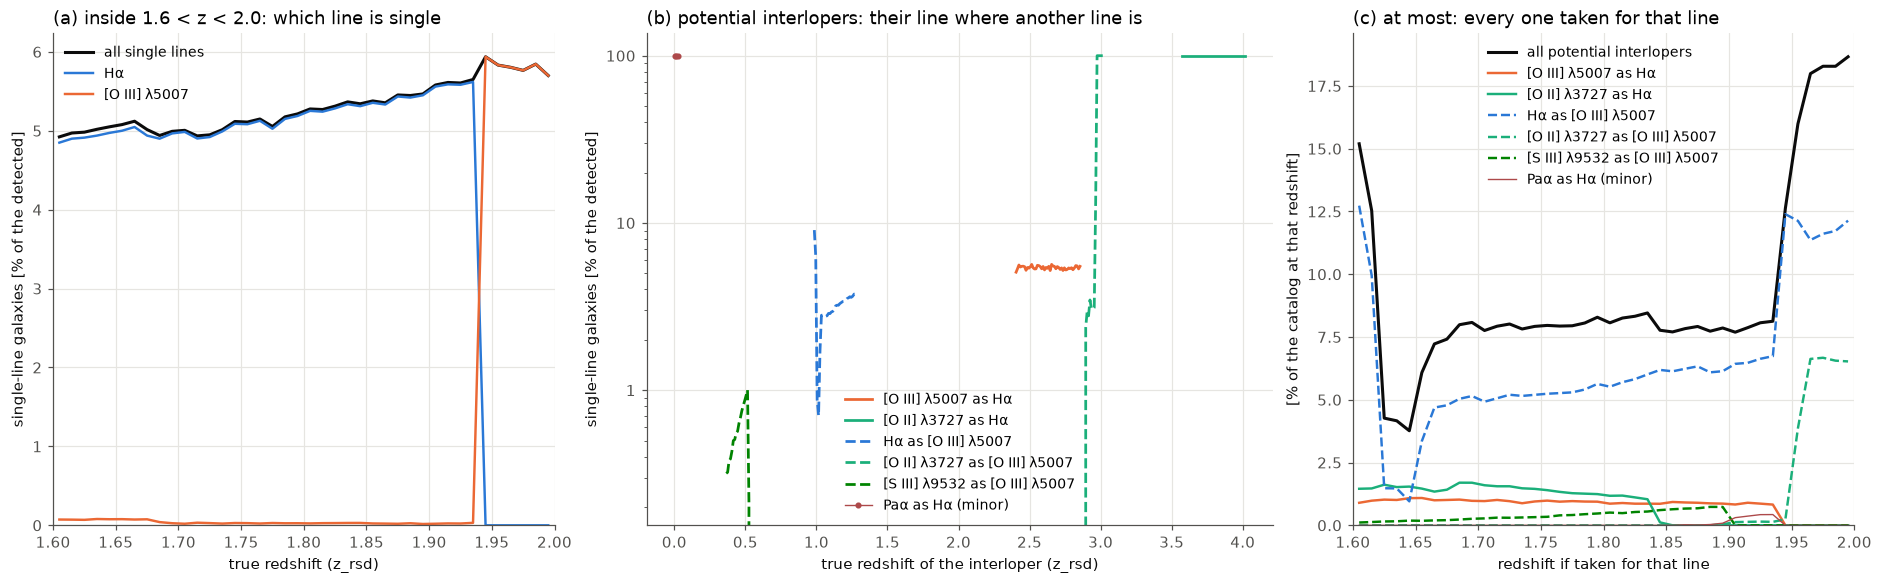

line="Ha": 9,025,787 galaxies with Ha detected at 1.6-2.0, before interlopers
line="OIII_5007": 9,164,666 galaxies with OIII_5007 detected at 1.6-2.0, before interlopers


In [2]:
proposal = base.make_proposal((1.6, 2.0), line="all", flux_limit=1.5e-16, secondary_flux_limit=6e-17, rescaling=RESCALING,
                              n_workers=N_WORKERS)
proposal.plot()
plt.show()
names = proposal.line_names
for line in ("Ha", "OIII_5007"):
    n = int(proposal.counts["n_line_det"][proposal.inside, names.index(line)].sum())
    print(f'line="{line}": {n:,} galaxies with {line} detected at 1.6-2.0, before interlopers')


For every galaxy at 1.6 < z < 2.0 (flux limits 1.5 / 0.6):

* **The sample** is 9.66 M detected galaxies (3,749 per deg²). `line="Ha"` would hold 9.03 M of them (Hα leaves the
  grism at z = 1.94), `line="OIII_5007"` 9.16 M.
* **(a) 5.2 % of the detected galaxies are single-line.** Below z = 1.94 the share rises from 4.9 to 5.7 %, nearly all
  Hα: [O III] is the single line in less than 0.1 %. Above, it is 5.7–5.9 %, all [O III], once Hα has left the grism.
* **(b) Five potential pairs**:
  * Hα at 0.98–1.29 taken for [O III]: 634,770 (246 per deg², 3.2 % of the detected galaxies there), at most 6.0 % of
    the catalog;
  * [O II] at 3.58–4.18 taken for Hα: 104,795 (41 per deg²), at most 0.99 %. [O II] is the only line in the bandpass
    there, so every detected galaxy is single-line;
  * [O III] at 2.41–2.85 taken for Hα: 92,477 (36 per deg², 5.4 % of the detected galaxies there), at most 0.87 %;
  * [O II] at 2.49–3.03 (40,338) and [S III] λ9532 at 0.37–0.58 (32,223) taken for [O III];
  * Paα at z < 0.03 taken for Hα is minor (3,973, the thin line).
* **(c) At most about 8 % of the catalog** over most of the range, and 8.6 % in all. The exceptions:
  * 15 % at z = 1.6, where Hα at z ≈ 1.0 passes for [O III];
  * 4 % at z = 1.62–1.65. The Hα galaxies that would land there are at z = 1.00–1.02, where [S III] λ9532 is still in
    the bandpass and confirms Hα;
  * 16–19 % above z = 1.95. Hα has left the grism, so the catalog holds half as many galaxies there, and [O II] at
    z ≈ 3 passes for [O III] as well.

### S/N thresholds instead of flux limits

S/N ≥ 5 for one line and ≥ 2 for the others in the Roman grism (one hour, twice the minimum zodiacal light), for the size
of each galaxy.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 48 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5 (other lines S/N ≥ 2), size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x
                min zodi
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 32 % of the detected
                galaxies with both lines in the bandpass
  sample        15,249,266 detected galaxies at 1.6 ≤ z < 2.0 (5,914 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  of all¹  of single¹
  ─────────  ────────  ───────  ──────────
  all         536,777   3.52 %
  Ha          377,458   2.48 %     70.32 %
  OIII_5007   159,319   1.04 %     29.68 %
  ¹ of the 15,249,266 galaxies detected at 1.6 ≤ z < 2.0 (true redshift), and of the 536,777
    sin

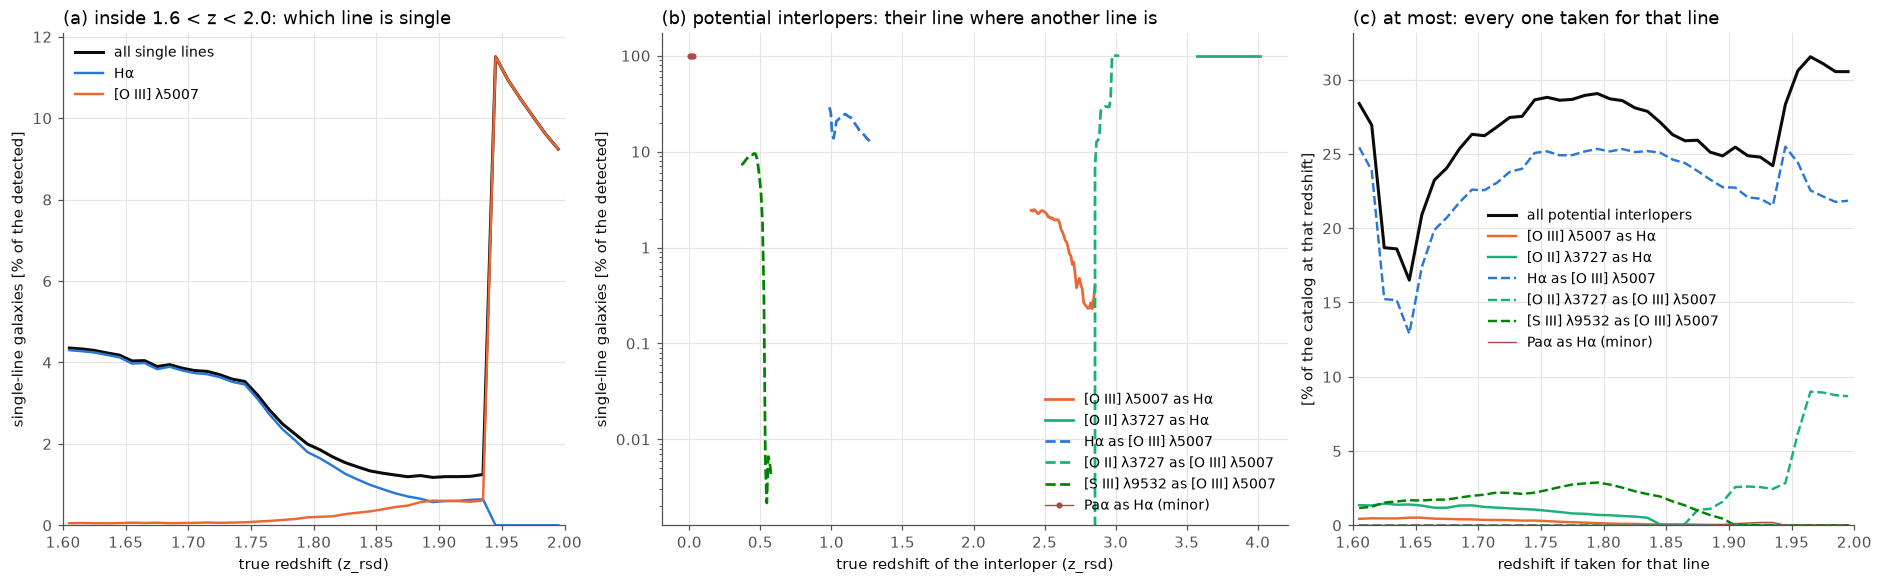

In [3]:
proposal_snr = base.make_proposal((1.6, 2.0), line="all", snr=5, secondary_snr=2, size="r50_disk_2d", rescaling=RESCALING,
                                  n_workers=N_WORKERS)
proposal_snr.plot()
plt.show()


With S/N ≥ 5 / 2 and the size of each galaxy:

* **The sample** is 15.25 M galaxies (5,914 per deg²), 58 % more than with the flux limits. At these wavelengths the
  S/N limit of compact galaxies is fainter than 1.5 × 10⁻¹⁶.
* **(a) 3.5 % single-line**: Hα in 2.5 %, [O III] in 1.0 %. The Hα share falls from about 4.3 % at z = 1.6 to 0.6 % at
  z = 1.93; above z = 1.94 [O III] is single in 9–11 %.
* **(b) The largest pair is Hα at 0.98–1.29 taken for [O III]**: 4.69 M (1,820 per deg²), at most 22.7 % of the
  catalog. There Hα falls at 13 000–15 000 Å, where the noise is low. Its companion [O III] falls at the noisy blue edge
  (9 900–11 500 Å) and misses S/N 2, the effect seen in notebook 01. Then come [S III] λ9532 (334 k), [O II] (192 k
  and 159 k) and [O III] at 2.41–2.85 (50 k); Paα taken for Hα is minor (2,836, the thin line).
* **(c)** At most 26 % of the catalog in all; 27 % in the worst case, which also loses the 537 k single lines of the
  range.

## Step 2: the identification and the catalog

For `line="all"` the template lists the pairs (true line → the line it is taken for) of the lines a single line can be
taken for. Some pairs, such as Hα and [O III] λ5007 taken for each other, do both: they move galaxies of other redshifts
into the range and galaxies of the range out of it. Such an entry gets `p_interloper`. Loss entries toward lines that
are not taken for here are left out. A confusion table does not depend on the wavelength, so "Hα taken for [O II]",
meant to lose Hα at 1.6 < z < 1.94, would also put the Hα of 0.52 < z < 0.70 at 1.68 < z < 2.0 as [O II]. Again an
assumed scenario of 5 % and 0.5 %, and then the line mix of the mock.

In [4]:
rows = proposal.confusion_template(p_interloper=0.05, p_target=0.005)     # an assumed scenario, not a Roman calibration
print(json.dumps(rows, indent=1))
cat = proposal.make_catalog(rows, OUT / "all_z1p6_2p0_matrix", n_workers=N_WORKERS)


{
 "Ha": {
  "OIII_5007": 0.05
 },
 "OIII_5007": {
  "Ha": 0.05
 },
 "OII_3727": {
  "Ha": 0.05,
  "OIII_5007": 0.05
 },
 "SIII_9532": {
  "OIII_5007": 0.05
 }
}
[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 31 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   confusion matrix: Ha → OIII_5007 0.05, OIII_5007 → Ha 0.05, OII_3727 → Ha 0.05,
                   OII_3727 → OIII_5007 0.05, SIII_9532 → OIII_5007 0.05
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                      number     share
  ─────────────────────────────────────────  ─────────  ────────
  multi-line                                 9,160,269   94.58 %
  single line, correct redshift                479,324    4.95 %
  single line taken for another: interloper   


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_matrix/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


In [5]:
cat_emp = proposal.make_catalog("empirical", OUT / "all_z1p6_2p0_empirical", n_workers=N_WORKERS)


[romanmock] line mix of the single-line galaxies: scanning 67 slices with 64 worker(s) …

 done in 26 s



── Line mix of the single-line galaxies (empirical identification) ─────────────────────────────────
  galaxies     5,126,254 single-line galaxies (F > 1.5e-16, other lines < 6e-17)
  bins         37 wavelength bins × 113–521 flux-rank bins (galaxies_per_bin 500)
  assignment   mode draw
  lines used   Ha, OIII_5007, OII_3727, SIII_9532, PaA

  λ_obs [Å]    galaxies  flux bins    Ha  OIII_5007  OII_3727  SIII_9532  PaA  brightest bin
  ───────────  ────────  ─────────  ────  ─────────  ────────  ─────────  ───  ───────────────
  10000–10251   184,546        369  78.1        0.5         ·       21.4    ·  SIII_9532 100 %
  10251–10503   260,692        521  69.1        0.5         ·       30.4    ·  SIII_9532 100 %
  10503–10754   201,661        403  98.0        0.7         ·        1.3    ·  SIII_9532 100 %
  10754–11005   199,297        398  99.2        0.7         ·        0.0    ·  OIII_5007 62 %
  11005–11257   210,310        420  99.3        0.7         ·        0.0    ·  OIII_500

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 31 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   the line mix of the mock (empirical)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                      number     share
  ─────────────────────────────────────────  ─────────  ────────
  multi-line                                 9,160,269   94.79 %
  single line, correct redshift                353,239    3.66 %
  single line taken for another: interloper    150,376    1.56 %
  all                                        9,663,884  100.00 %

── Lines in the bandpass, 10000


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_empirical/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


## What is in the catalog

The components of the two catalogs (notebook 01 explains `id_outcome`, `line_true` and `line_assigned`), with one entry
per kind of interloper, and their dN/dz against the assigned redshift. A kind of interloper has the colour of its true
line and one line style per line it is taken for.

(a) assumed confusion table: 9,685,402 galaxies
  all                        9,685,402   100.000 %


  multi_line                 9,160,269    94.578 %


  single_correct               479,324     4.949 %
  galaxies                   9,639,593    99.527 %
  interlopers                   45,809     0.473 %
  Ha_as_OIII_5007               32,183     0.332 %
  OII_3727_as_Ha                 5,393     0.056 %
  OIII_5007_as_Ha                4,609     0.048 %
  OII_3727_as_OIII_5007          2,088     0.022 %


  SIII_9532_as_OIII_5007         1,536     0.016 %
(b) line mix of the mock: 9,663,884 galaxies
  all                        9,663,884   100.000 %


  multi_line                 9,160,269    94.789 %


  single_correct               353,239     3.655 %
  galaxies                   9,513,508    98.444 %
  interlopers                  150,376     1.556 %
  OIII_5007_as_Ha               67,803     0.702 %
  OII_3727_as_Ha                49,462     0.512 %
  Ha_as_OIII_5007               26,183     0.271 %
  OII_3727_as_OIII_5007          6,272     0.065 %
  PaA_as_Ha                        432     0.004 %


  SIII_9532_as_OIII_5007           224     0.002 %


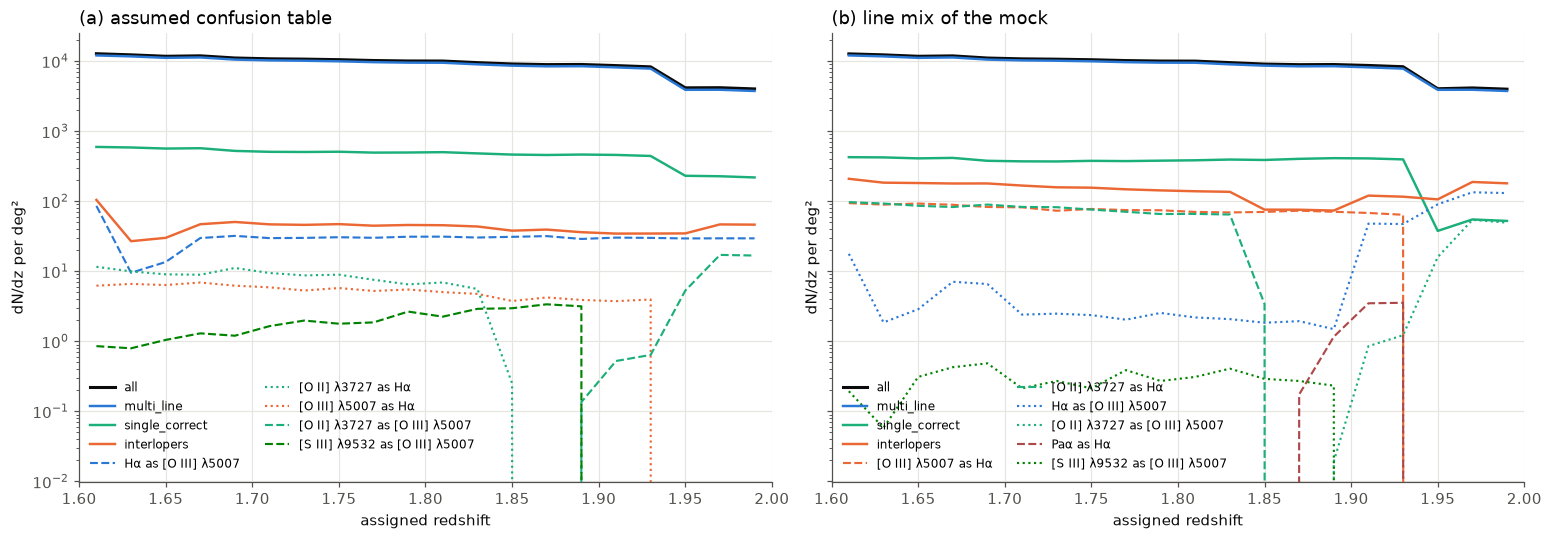

In [6]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


edges = np.linspace(1.6, 2.0, 21)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, sharey=True)
show_components(cat, "(a) assumed confusion table", axes[0], edges)
show_components(cat_emp, "(b) line mix of the mock", axes[1], edges)
plt.show()


The two catalogs share their 9.16 M multi-line galaxies (94.6–94.8 %):

* **(a) The assumed table** gives 45,809 interlopers (0.47 %), 5 % of each of the five potential pairs: 32,183 Hα
  taken for [O III], 5,393 [O II] and 4,609 [O III] taken for Hα, and 2,088 [O II] and 1,536 [S III] λ9532 taken
  for [O III]. These are exactly the kinds the proposal lists.
* **(b) The line mix of the mock** gives 150,376 interlopers (1.6 %), three times as many. At 17 000–19 300 Å the
  single lines of the mock are 60–84 % Hα, so most single [O III] and [O II] lines there are taken for Hα: 67,803
  [O III] from z > 2.4 and 49,462 [O II] from z > 3.6. The others are 26,183 Hα taken for [O III], 6,272 [O II] and
  224 [S III] λ9532 taken for [O III], and 432 Paα (z < 0.03) taken for Hα. 70 % of the single-line galaxies inside
  the range keep a correct redshift (353,239 of 504,589).

In both catalogs every part drops at z = 1.94, where Hα leaves the grism: the catalog holds half as many galaxies above
it. The [O III] taken for Hα stop there, since no galaxy is assigned Hα above z = 1.94. With the line mix of the mock
the single-line galaxies with a correct redshift fall by about eight times at z = 1.94. Their single line is [O III]
at 14 700–15 000 Å, where most single lines of the mock are Hα or [O II], so most of them are taken for another line
and leave the range.

## The files

As in notebook 01: `<name>.hdf5`, `<name>_summary.json` and `<name>_proposal.npz` in each directory, with the default
name `all_z1p6_2p0`.

In [7]:
for d in ("all_z1p6_2p0_matrix", "all_z1p6_2p0_empirical"):
    print(d + ":", ", ".join(sorted(p.name for p in (OUT / d).iterdir() if p.is_file())))
back = Catalog.read(OUT / "all_z1p6_2p0_empirical" / "all_z1p6_2p0.hdf5")
print(f"read back: {len(back):,} galaxies; columns {', '.join(back.columns)}")


all_z1p6_2p0_matrix: all_z1p6_2p0.hdf5, all_z1p6_2p0_proposal.npz, all_z1p6_2p0_summary.json
all_z1p6_2p0_empirical: all_z1p6_2p0.hdf5, all_z1p6_2p0_proposal.npz, all_z1p6_2p0_summary.json
read back: 9,663,884 galaxies; columns gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome, line_true, line_assigned, n_det


## Summary

* At 1.6 < z < 2.0 the catalog of every galaxy (`line="all"`) holds 9.66 M galaxies at flux limits 1.5 / 0.6. Of them
  5.2 % are single-line, and five potential pairs could make at most 8.6 % of the catalog; 9.02 % in the worst case,
  where every single line is an interloper (notebook 06).
* With S/N 5 / 2 it holds 15.2 M galaxies, at most 26 % interlopers, mostly Hα at z ≈ 1 taken for [O III].
* The assumed table gives 45,809 interlopers (0.47 %), the line mix of the mock 150,376 (1.6 %), 45 % of them [O III]
  at z > 2.4 taken for Hα.
* The notebook ran in 2.6 minutes on a CPU node.